In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
con = duckdb.connect("../olist.duckdb", read_only=True)

In [2]:
con.sql("""
SELECT COUNT(*) AS pedidos,
  ROUND(100.0 * AVG((CAST(dt_entrega AS DATE) > CAST(dt_prometida AS DATE))::INT), 2) AS pct_atraso_por_data,
  ROUND(100.0 * AVG((dt_entrega > dt_prometida)::INT), 2)                             AS pct_atraso_por_timestamp
FROM analitica_pedidos
""").df()

,pedidos,pct_atraso_por_data,pct_atraso_por_timestamp
0,96470,6.77,8.11


In [3]:
con.sql("""
SELECT COUNT(*) AS atrasados,
  ROUND(AVG(dias_atraso), 1)         AS media_dias,
  median(dias_atraso)                AS mediana_dias,
  quantile_cont(dias_atraso, 0.9)    AS p90_dias,
  SUM((dias_atraso > 7)::INT)        AS mais_de_7_dias,
  SUM((dias_atraso > 15)::INT)       AS mais_de_15_dias
FROM analitica_pedidos WHERE atrasado
""").df()

,atrasados,media_dias,mediana_dias,p90_dias,mais_de_7_dias,mais_de_15_dias
0,6534,10.6,7.0,22.0,2862.0,1225.0


In [4]:
con.sql("""
SELECT customer_state AS estado, COUNT(*) AS pedidos,
  ROUND(100.0 * AVG(atrasado::INT), 2)  AS pct_atraso,
  ROUND(AVG(prazo_prometido_dias), 1)   AS prazo_prometido_medio,
  ROUND(AVG(prazo_real_dias), 1)        AS prazo_real_medio
FROM analitica_pedidos
GROUP BY 1 ORDER BY pct_atraso DESC
""").df()

,estado,pedidos,pct_atraso,prazo_prometido_medio,prazo_real_medio
0,AL,397,21.41,33.2,24.5
1,MA,717,17.43,31.1,21.5
2,SE,335,15.22,31.5,21.5
3,PI,476,13.87,30.7,19.4
4,CE,1279,13.76,32.0,21.2
5,RR,41,12.20,46.6,29.3
6,BA,3256,12.16,30.1,19.3
7,RJ,12350,12.11,27.0,15.2
8,PA,946,11.21,37.8,23.7
9,ES,1995,10.73,26.2,15.7


In [5]:
con.sql("""
SELECT strftime(dt_compra, '%Y-%m') AS mes, COUNT(*) AS pedidos,
  ROUND(100.0 * AVG(atrasado::INT), 2) AS pct_atraso
FROM analitica_pedidos GROUP BY 1 ORDER BY 1
""").df()

,mes,pedidos,pct_atraso
0,2016-09,1,100.00
1,2016-10,265,0.75
2,2016-12,1,0.00
3,2017-01,750,2.93
4,2017-02,1653,2.96
5,2017-03,2546,4.56
6,2017-04,2303,6.56
7,2017-05,3545,2.99
8,2017-06,3135,3.03
9,2017-07,3872,2.79


In [6]:
con.sql("""
SELECT (customer_state = seller_state) AS mesmo_estado, COUNT(*) AS pedidos,
  ROUND(100.0 * AVG(atrasado::INT), 2) AS pct_atraso,
  ROUND(AVG(prazo_real_dias), 1)       AS prazo_real_medio
FROM analitica_pedidos WHERE seller_state IS NOT NULL
GROUP BY 1
""").df()

,mesmo_estado,pedidos,pct_atraso,prazo_real_medio
0,False,61780,8.05,15.1
1,True,34690,4.51,7.9


In [7]:
con.sql("""
WITH rev AS (
  SELECT order_id, AVG(review_score) AS nota FROM order_reviews GROUP BY order_id
)
SELECT a.atrasado, COUNT(*) AS pedidos,
  ROUND(AVG(r.nota), 2)                     AS nota_media,
  ROUND(100.0 * AVG((r.nota <= 2)::INT), 2) AS pct_nota_baixa
FROM analitica_pedidos a JOIN rev r ON r.order_id = a.order_id
GROUP BY 1
""").df()

,atrasado,pedidos,nota_media,pct_nota_baixa
0,True,6381,2.27,62.36
1,False,89443,4.29,9.23


In [8]:
con.sql("""
WITH e AS (
  SELECT customer_state AS estado, COUNT(*) AS pedidos,
         COUNT(*) FILTER (WHERE atrasado) AS atrasados
  FROM analitica_pedidos GROUP BY 1
)
SELECT estado, pedidos, atrasados,
  ROUND(100.0 * atrasados / pedidos, 2) AS pct_atraso,
  ROUND(100.0 * atrasados / SUM(atrasados) OVER (), 1) AS pct_do_total,
  ROUND(100.0 * SUM(atrasados) OVER (ORDER BY atrasados DESC
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
        / SUM(atrasados) OVER (), 1) AS pct_acumulado
FROM e ORDER BY atrasados DESC
""").df()

,estado,pedidos,atrasados,pct_atraso,pct_do_total,pct_acumulado
0,SP,40494,1820,4.49,27.9,27.9
1,RJ,12350,1495,12.11,22.9,50.7
2,MG,11354,519,4.57,7.9,58.7
3,BA,3256,396,12.16,6.1,64.7
4,RS,5344,325,6.08,5.0,69.7
5,SC,3546,291,8.21,4.5,74.2
6,ES,1995,214,10.73,3.3,77.4
7,PR,4923,199,4.04,3.0,80.5
8,CE,1279,176,13.76,2.7,83.2
9,PE,1593,153,9.60,2.3,85.5


In [9]:
con.sql("""
SELECT customer_state AS estado, COUNT(*) AS pedidos,
  ROUND(AVG(prazo_prometido_dias - prazo_real_dias), 1) AS folga_media_dias,
  ROUND(stddev_samp(prazo_real_dias), 1)                AS desvio_prazo_real,
  ROUND(100.0 * AVG(atrasado::INT), 2)                  AS pct_atraso
FROM analitica_pedidos
GROUP BY 1 HAVING COUNT(*) >= 100
ORDER BY pct_atraso DESC
""").df()

,estado,pedidos,folga_media_dias,desvio_prazo_real,pct_atraso
0,AL,397,8.7,11.5,21.41
1,MA,717,9.6,11.4,17.43
2,SE,335,10.0,16.8,15.22
3,PI,476,11.3,14.7,13.87
4,CE,1279,10.8,13.1,13.76
5,BA,3256,10.8,11.7,12.16
6,RJ,12350,11.8,11.5,12.11
7,PA,946,14.1,13.2,11.21
8,ES,1995,10.5,10.7,10.73
9,PB,517,13.3,10.9,10.44


In [10]:
con.sql("""
WITH rev AS (
  SELECT order_id, AVG(review_score) AS nota FROM order_reviews GROUP BY order_id
)
SELECT
  CASE WHEN a.dias_atraso <= -8 THEN '1. adiantado 8+ dias'
       WHEN a.dias_atraso <= 0  THEN '2. adiantado até 7 dias ou no prazo'
       WHEN a.dias_atraso <= 3  THEN '3. atraso 1-3 dias'
       WHEN a.dias_atraso <= 7  THEN '4. atraso 4-7 dias'
       WHEN a.dias_atraso <= 15 THEN '5. atraso 8-15 dias'
       ELSE '6. atraso 16+ dias' END AS faixa,
  COUNT(*) AS pedidos,
  ROUND(AVG(r.nota), 2)                     AS nota_media,
  ROUND(100.0 * AVG((r.nota <= 2)::INT), 1) AS pct_nota_baixa
FROM analitica_pedidos a JOIN rev r ON r.order_id = a.order_id
GROUP BY 1 ORDER BY 1
""").df()

,faixa,pedidos,nota_media,pct_nota_baixa
0,1. adiantado 8+ dias,70929,4.32,8.9
1,2. adiantado até 7 dias ou no prazo,18514,4.19,10.3
2,3. atraso 1-3 dias,1852,3.29,32.2
3,4. atraso 4-7 dias,1748,2.11,67.6
4,5. atraso 8-15 dias,1601,1.68,80.0
5,6. atraso 16+ dias,1180,1.73,78.1


In [11]:
con.sql("""
SELECT strftime(dt_compra, '%Y-%m') AS mes, COUNT(*) AS pedidos,
  ROUND(AVG(date_diff('day', CAST(dt_compra AS DATE), CAST(dt_postagem AS DATE))), 1) AS dias_ate_postagem,
  ROUND(AVG(date_diff('day', CAST(dt_postagem AS DATE), CAST(dt_entrega AS DATE))), 1) AS dias_transporte,
  ROUND(AVG(prazo_prometido_dias), 1) AS prazo_prometido,
  ROUND(100.0 * AVG(atrasado::INT), 2) AS pct_atraso
FROM analitica_pedidos
WHERE NOT data_inconsistente AND dt_postagem IS NOT NULL
  AND dt_compra >= '2017-01-01'
GROUP BY 1 ORDER BY 1
""").df()

,mes,pedidos,dias_ate_postagem,dias_transporte,prazo_prometido,pct_atraso
0,2017-01,749,3.6,9.2,40.1,2.94
1,2017-02,1651,3.8,9.5,32.5,2.97
2,2017-03,2545,3.2,9.8,25.4,4.56
3,2017-04,2303,3.8,11.2,28.0,6.56
4,2017-05,3544,3.1,8.3,24.9,2.99
5,2017-06,3134,3.2,8.8,24.7,3.03
6,2017-07,3861,3.0,8.5,24.0,2.80
7,2017-08,4191,3.0,8.1,24.1,2.91
8,2017-09,4149,3.1,8.6,23.1,4.36
9,2017-10,4478,3.3,8.4,23.7,4.18


In [12]:
con.sql("""
SELECT strftime(dt_compra, '%Y-%m') AS mes,
  COUNT(*) FILTER (WHERE customer_state = 'RJ') AS pedidos_rj,
  ROUND(100.0 * AVG(atrasado::INT) FILTER (WHERE customer_state = 'RJ'), 2) AS pct_atraso_rj,
  ROUND(100.0 * AVG(atrasado::INT) FILTER (WHERE customer_state = 'SP'), 2) AS pct_atraso_sp,
  ROUND(100.0 * AVG(atrasado::INT) FILTER (WHERE customer_state NOT IN ('RJ','SP')), 2) AS pct_atraso_resto
FROM analitica_pedidos
WHERE dt_compra >= '2017-01-01'
GROUP BY 1 ORDER BY 1
""").df()

,mes,pedidos_rj,pct_atraso_rj,pct_atraso_sp,pct_atraso_resto
0,2017-01,91,3.30,2.83,2.93
1,2017-02,230,3.48,3.00,2.80
2,2017-03,370,4.32,2.28,6.45
3,2017-04,325,6.46,6.99,6.24
4,2017-05,466,2.79,4.26,2.04
5,2017-06,399,3.26,3.27,2.75
6,2017-07,547,3.11,1.81,3.54
7,2017-08,537,2.98,2.04,3.62
8,2017-09,591,5.08,3.11,5.19
9,2017-10,654,6.88,3.25,4.09


In [13]:
con.sql("""
SELECT k AS dias_extra_no_prazo,
       COUNT(*) FILTER (WHERE dias_atraso > k)       AS atrasados,
       ROUND(100.0 * AVG((dias_atraso > k)::INT), 2) AS pct_atraso
FROM analitica_pedidos, range(0, 8) AS t(k)
GROUP BY 1 ORDER BY 1
""").df()

,dias_extra_no_prazo,atrasados,pct_atraso
0,0,6534,6.77
1,1,5709,5.92
2,2,5164,5.35
3,3,4664,4.83
4,4,4211,4.37
5,5,3764,3.90
6,6,3345,3.47
7,7,2862,2.97


In [14]:
con.sql("""
SELECT strftime(dt_compra, '%Y-%m') AS mes,
  ROUND(AVG(prazo_prometido_dias) FILTER (WHERE customer_state = 'RJ'), 1) AS prometido_rj,
  ROUND(AVG(prazo_real_dias)      FILTER (WHERE customer_state = 'RJ'), 1) AS real_rj,
  ROUND(AVG(prazo_prometido_dias) FILTER (WHERE customer_state = 'SP'), 1) AS prometido_sp,
  ROUND(AVG(prazo_real_dias)      FILTER (WHERE customer_state = 'SP'), 1) AS real_sp
FROM analitica_pedidos
WHERE dt_compra >= '2017-01-01'
GROUP BY 1 ORDER BY 1
""").df()

,mes,prometido_rj,real_rj,prometido_sp,real_sp
0,2017-01,39.7,14.0,37.2,10.6
1,2017-02,32.1,12.6,29.0,10.0
2,2017-03,24.9,10.8,22.3,9.7
3,2017-04,27.0,14.3,24.8,12.1
4,2017-05,25.1,11.2,20.4,9.0
5,2017-06,25.4,12.5,20.2,9.3
6,2017-07,24.5,12.3,19.5,7.9
7,2017-08,24.6,12.3,19.5,7.3
8,2017-09,22.8,12.8,19.0,8.3
9,2017-10,23.3,13.0,19.2,8.2


In [15]:
con.sql("""
WITH seg AS (
  SELECT CASE WHEN customer_state = 'RJ' THEN 'RJ'
              WHEN customer_state IN ('AL','MA','SE','PI','CE','BA','PE','PB','RN') THEN 'Nordeste'
              ELSE 'Resto' END AS segmento,
         dias_atraso
  FROM analitica_pedidos
)
SELECT segmento, COUNT(*) AS pedidos,
  COUNT(*) FILTER (WHERE dias_atraso > 0) AS atrasados_hoje,
  COUNT(*) FILTER (WHERE dias_atraso > 3) AS atrasados_com_3_dias,
  ROUND(1000.0 * (COUNT(*) FILTER (WHERE dias_atraso > 0)
                - COUNT(*) FILTER (WHERE dias_atraso > 3)) / COUNT(*), 1) AS evitados_por_1000_pedidos
FROM seg GROUP BY 1 ORDER BY 5 DESC
""").df()

,segmento,pedidos,atrasados_hoje,atrasados_com_3_dias,evitados_por_1000_pedidos
0,Nordeste,9044,1150,899,27.8
1,RJ,12350,1495,1198,24.0
2,Resto,75076,3889,2567,17.6


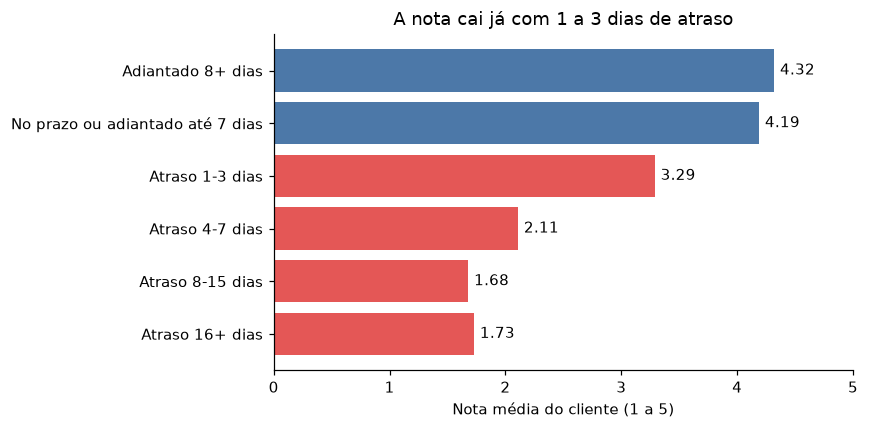

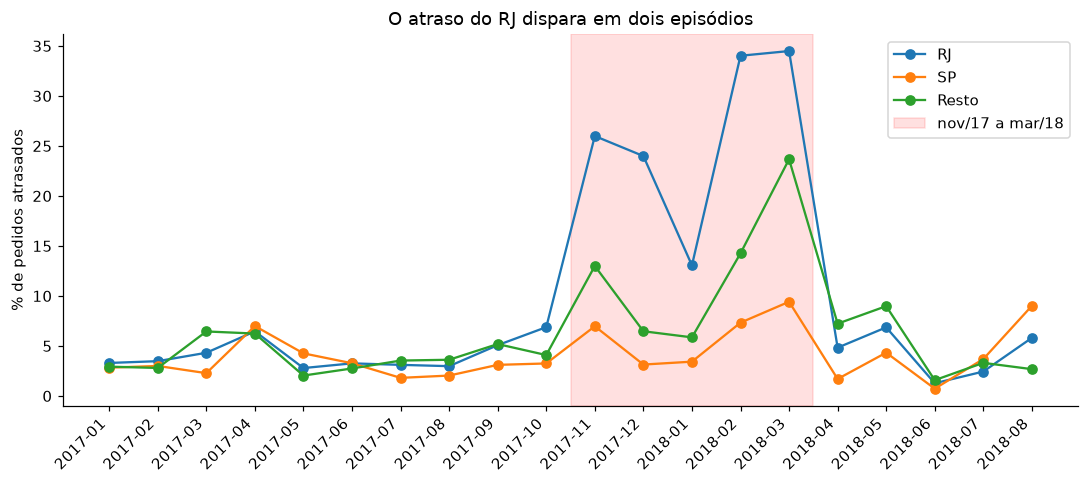

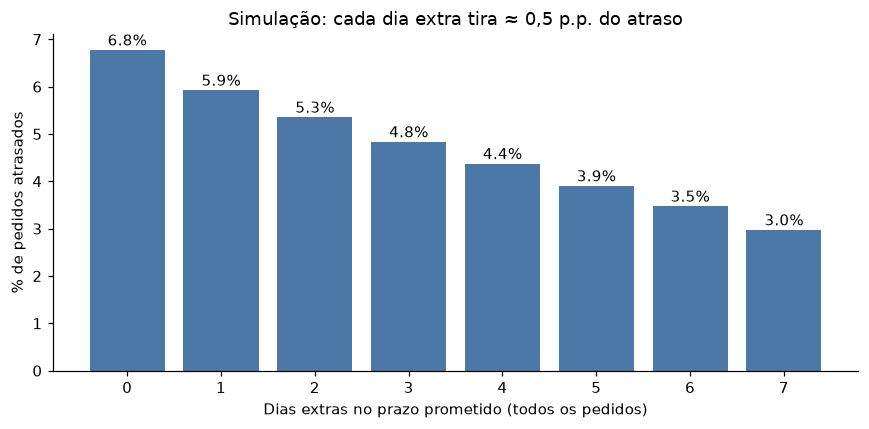

In [16]:
from pathlib import Path
Path("../images").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# 1) Nota por faixa de atraso
df1 = con.sql("""
WITH rev AS (SELECT order_id, AVG(review_score) AS nota FROM order_reviews GROUP BY order_id)
SELECT CASE WHEN a.dias_atraso <= -8 THEN 'Adiantado 8+ dias'
            WHEN a.dias_atraso <= 0  THEN 'No prazo ou adiantado até 7 dias'
            WHEN a.dias_atraso <= 3  THEN 'Atraso 1-3 dias'
            WHEN a.dias_atraso <= 7  THEN 'Atraso 4-7 dias'
            WHEN a.dias_atraso <= 15 THEN 'Atraso 8-15 dias'
            ELSE 'Atraso 16+ dias' END AS faixa,
       MIN(a.dias_atraso) AS ordem,
       ROUND(AVG(r.nota), 2) AS nota_media
FROM analitica_pedidos a JOIN rev r ON r.order_id = a.order_id
GROUP BY 1 ORDER BY 2
""").df()
cores = ["#E45756" if "Atraso" in f else "#4C78A8" for f in df1["faixa"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(df1["faixa"], df1["nota_media"], color=cores)
ax.invert_yaxis()
for i, v in enumerate(df1["nota_media"]):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 5)
ax.set_xlabel("Nota média do cliente (1 a 5)")
ax.set_title("A nota cai já com 1 a 3 dias de atraso")
plt.tight_layout()
plt.savefig("../images/01_nota_por_faixa.png")
plt.show()

# 2) Atraso por mês: RJ, SP e resto
df2 = con.sql("""
SELECT strftime(dt_compra, '%Y-%m') AS mes,
  ROUND(100.0 * AVG(atrasado::INT) FILTER (WHERE customer_state = 'RJ'), 2) AS RJ,
  ROUND(100.0 * AVG(atrasado::INT) FILTER (WHERE customer_state = 'SP'), 2) AS SP,
  ROUND(100.0 * AVG(atrasado::INT) FILTER (WHERE customer_state NOT IN ('RJ','SP')), 2) AS Resto
FROM analitica_pedidos WHERE dt_compra >= '2017-01-01'
GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(10, 4.5))
for col in ["RJ", "SP", "Resto"]:
    ax.plot(range(len(df2)), df2[col], marker="o", label=col)
i0 = df2.index[df2["mes"] == "2017-11"][0]
i1 = df2.index[df2["mes"] == "2018-03"][0]
ax.axvspan(i0 - 0.5, i1 + 0.5, alpha=0.12, color="red", label="nov/17 a mar/18")
ax.set_xticks(range(len(df2)))
ax.set_xticklabels(df2["mes"], rotation=45, ha="right")
ax.set_ylabel("% de pedidos atrasados")
ax.set_title("O atraso do RJ dispara em dois episódios")
ax.legend()
plt.tight_layout()
plt.savefig("../images/02_atraso_rj_sp_resto.png")
plt.show()

# 3) Simulação de prazo
df3 = con.sql("""
SELECT k AS dias_extra, ROUND(100.0 * AVG((dias_atraso > k)::INT), 2) AS pct_atraso
FROM analitica_pedidos, range(0, 8) AS t(k)
GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df3["dias_extra"], df3["pct_atraso"], color="#4C78A8")
for x, y in zip(df3["dias_extra"], df3["pct_atraso"]):
    ax.text(x, y + 0.1, f"{y:.1f}%", ha="center")
ax.set_xticks(df3["dias_extra"])
ax.set_xlabel("Dias extras no prazo prometido (todos os pedidos)")
ax.set_ylabel("% de pedidos atrasados")
ax.set_title("Simulação: cada dia extra tira ≈ 0,5 p.p. do atraso")
plt.tight_layout()
plt.savefig("../images/03_simulacao_prazo.png")
plt.show()